## Setup

In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch


In [ ]:
# Load dataset from local drive
from datasets import Dataset, Image, load_dataset
dataset = load_dataset("realwaste-data/RealWaste", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous', 'Paper', 'Plastic', 'Textile', 'Vegetation']
Number of images: 4752


In [ ]:
# Load CLIP processor and model
from transformers import CLIPProcessor, CLIPModel

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 67173.67it/s]


## Sample classification run

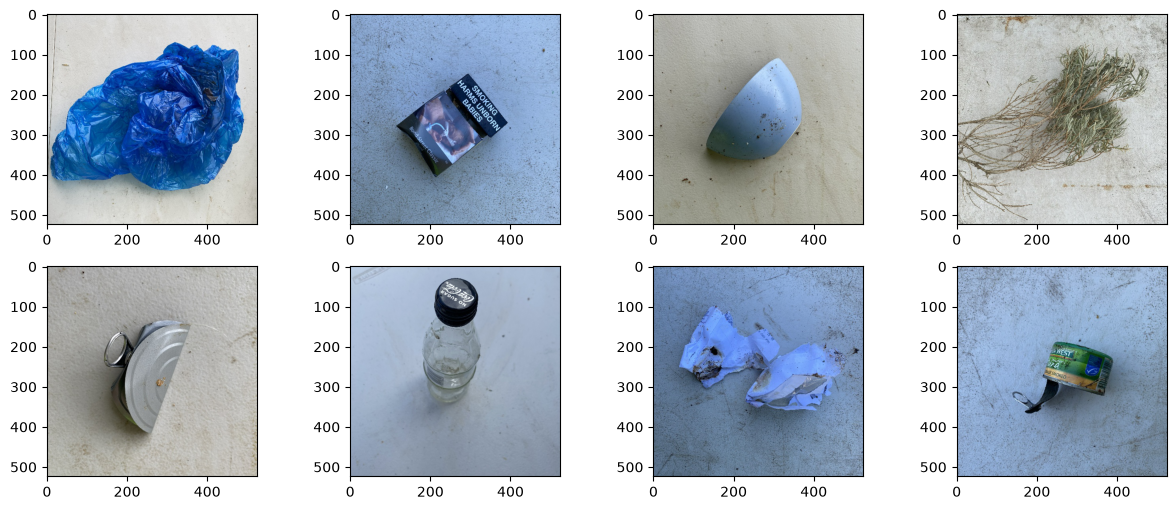

In [4]:
sample = dataset.shuffle(seed=42)[:8]
images = sample["image"]
true_labels = sample["label"]

plt.figure(figsize=(15, 6))
for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)

In [5]:
inputs = processor(images=images, text=labels, return_tensors="pt", padding=True)
outputs = model(**inputs)

logits_per_image = outputs.logits_per_image
probs = logits_per_image.softmax(dim=1)
predictions = probs.argmax(dim=1)

In [7]:
predicted_labels = [labels[id] for id in predictions]
predicted_labels

['Plastic',
 'Paper',
 'Glass',
 'Vegetation',
 'Metal',
 'Glass',
 'Paper',
 'Plastic']

In [ ]:
# Wrap the label prediction steps (above) into a function for quick use
from typing import List
def predict_labels(images: List, labels:List[str]=labels, processor=processor, model=model):
    """
    Process and predict the class of a set of images, given a set of possible labels. Especially designed for zero-shot classification.

    Parameters
    ----------
    images : List
        A list of images to be classified
    labels : List[str]
        A list of strings containing the possible classes
    processor
        The processor to be used to transform images and labels into numerical embeddings
    model
        The model to be used to predict class labels

    Returns
    -------
    predictions : List
        A list of the label indexes predicted for the list of input images
    predicted_labels : List
        A list of the labels predicted for the list of input images
    """
    
    inputs = processor(images=images, text=labels, return_tensors="pt", padding=True)
    outputs = model(**inputs)

    logits_per_image = outputs.logits_per_image
    probs = logits_per_image.softmax(dim=1)
    predictions = probs.argmax(dim=1).tolist()
    predicted_labels = [labels[id] for id in predictions]

    return predictions, predicted_labels


In [23]:
predict_labels(images)

([6, 5, 2, 8, 3, 2, 5, 6],
 ['Plastic',
  'Paper',
  'Glass',
  'Vegetation',
  'Metal',
  'Glass',
  'Paper',
  'Plastic'])

## Predict on Dataset

In [ ]:
# Split dataset into train and test
data_split = dataset.train_test_split(0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]